# Decomposing the Generalization Error

## About This Project

In this project, you will decompose the test loss into its constituent components &mdash; bias, variance, noise &mdash; and analyze their behavior.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

Before you get started, let's import a few packages that you will need.

In [3]:
import numpy as np
from numpy.matlib import repmat

# Non-interactive plots
%matplotlib inline
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


## Variance + Bias + Noise Decomposition of Generalized Error

Recall that the generalization error of squared loss can be decomposed into bias, variance, and noise:

$$
\underbrace{\mathbb{E}\left[\left(h_D(\mathbf{x}) - y\right)^2\right]}_{\text{Generalization Error}} = \underbrace{\mathbb{E}\left[\left(h_D(\mathbf{x}) - \overline{h}(\mathbf{x})\right)^2\right]}_{\text{Variance}} 
+ \underbrace{\mathbb{E}\left[\left(\overline{h}(\mathbf{x}) - \overline{y}(\mathbf{x})\right)^2\right]}_{\text{Bias}^2} 
+ \underbrace{\mathbb{E} \left[ \left( \overline{y}(\mathbf{x}) - y(\mathbf{x}) \right)^2 \right]}_{\text{Noise}}
$$
    
We will now create a data set for which we can approximately compute this decomposition. Since we cannot calculate the Generalization Error, we will estimate it using the loss on the test set. The function **`toy_data`** generates a two-dimensional binary data set (classes 1 and 2). Both are sampled from Gaussian distributions:

$$
P(\mathbf{x}|y=1) \sim \mathcal{N}(\boldsymbol{0},I)
\quad\text{and}\quad 
P( \mathbf{x}|y=2) \sim \mathcal{N}(\boldsymbol{\mu},I),
$$

where $\boldsymbol{\mu} = \begin{bmatrix} 1.75 \\ 1.75 \end{bmatrix}$. In code, we will use the global variable `OFFSET = 1.75` to represent the components of $\boldsymbol{\mu}$.

### Computing Noise, Bias, and Variance

You will implement five functions: **`compute_ybar`**, **`compute_noise`**, **`compute_hbar`**, **`compute_bias`**, and **`compute_variance`**. The functions `compute_ybar` and `compute_hbar` are helper functions to calculate the three components of mean squared error.

`toy_data` is a helper function that generates the $n$ two-dimensional data points with $\frac{n}{2}$ values in class 1 and $\frac{n}{2}$ values in class 2.

- **Class 1** is the label for data drawn from a normal distribution with mean $\boldsymbol{0} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$ and standard deviation $\boldsymbol{\sigma} = \mathbf{I} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$. That is, the first dimension is drawn with mean $0$ and standard deviation $1$, and the second dimension is independently drawn with mean $0$ and standard deviation $1$.

- **Class 2** is the label for data drawn from a normal distribution with mean $\boldsymbol{\mu} = \begin{bmatrix} 1.75 \\ 1.75 \end{bmatrix}$ and standard deviation $\boldsymbol{\sigma} = \mathbf{I} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$. That is, first dimension is drawn with mean $1.75$ and standard deviation $1$, and second dimension is independelty drawn with mean $1.75$ and standard deviation $1$.

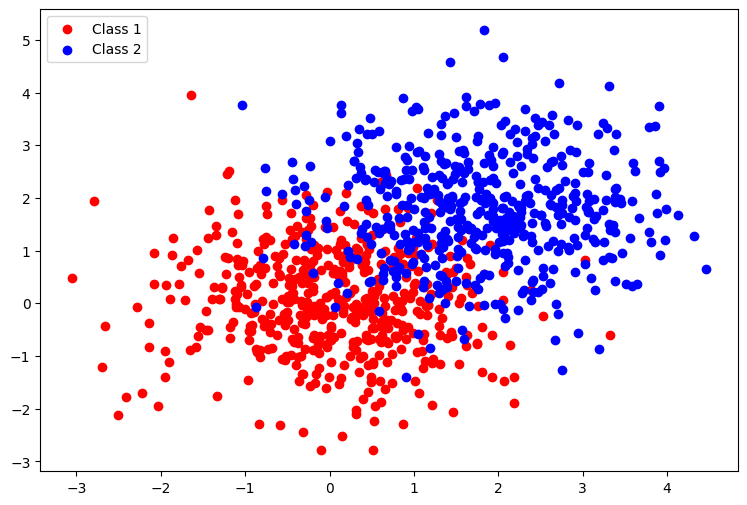

In [4]:
OFFSET = 1.75  # mu = [OFFSET, OFFSET]
np.random.seed(1)
X, y = toy_data(OFFSET, 1000)

# Visualize the generated data
ind1 = y == 1
ind2 = y == 2
plt.figure(figsize=(9, 6))
plt.scatter(X[ind1, 0], X[ind1, 1], c="red", marker="o", label="Class 1")
plt.scatter(X[ind2, 0], X[ind2, 1], c="blue", marker="o", label="Class 2")
plt.legend(loc="upper left")
plt.show()

### Part One: Noise [Graded]

You will first implement functions to compute the noise. For this, you need to implement **`compute_ybar`** to compute the expected label for a given input $\mathbf{x}$:

$$
\overline{y}(\mathbf{x}) = 1\cdot P(y=1|\mathbf{x}) + 2\cdot P(y=2|\mathbf{x})
$$

You can compute the probability $P(\mathbf{x}|y=c)$ using $P(\mathbf{x}|y=1)\sim\mathcal{N}(\boldsymbol{0},I)$ and $P(\mathbf{x}|y=2)\sim\mathcal{N}(\boldsymbol{\mu},I)$. Then use Bayes' rule to compute

$$
P(y=c|\mathbf{x}) = \frac{P(\mathbf{x}|y=c)\cdot P(y=c)}{P(\mathbf{x}|y=1)\cdot P(y=1) + P(\mathbf{x}|y=2)\cdot P(y=2)}
$$

**Implementation Notes:**

- Use the function `normpdf` to compute $P([\mathbf{x}]_{\alpha}|y=c)$, which is defined for you inside `compute_ybar`. Note that `normpdf` only computes $P([\mathbf{x}]_{\alpha}|y= c)$ in a single dimension $\alpha$, but you can use the fact that both dimensions are independent to obtain. For example, 

$$
P(\mathbf{x}|y=1) = P([\mathbf{x}]_1|y=1)\cdot P([\mathbf{x}]_2|y=1)
$$

- Since `toy_data` generated $\frac{n}{2}$ points for both classes, $P(y=c) = \frac{1}{2}$ for $c = 1,2$.

In [5]:
def compute_ybar(xTe, OFFSET):
    """
    Computes the expected label ybar for a set of inputs xTe,
    generated from two normal distributions:
    1. the first with mean [0, 0] and standard deviation I, and
    2. the second with mean [OFFSET, OFFSET] and standard deviation I

    Input:
        xTe: Data matrix of shape nx2
        OFFSET: The OFFSET passed into the toyData function. The difference in the
                mu of normal distributions for points with labels class1 and class2.

    Output:
        ybar: nx1 vector of the expected labels for each vector in xTe
    """
    n, d = xTe.shape
    ybar = np.empty(n)  # Initialize variable to be returned

    # Feel free to use the following function to compute P([x]_\alpha | y)
    norm_pdf = lambda x, mu, sigma: np.exp(-0.5 * np.power((x - mu) / sigma, 2)) / (
        np.sqrt(2 * np.pi) * sigma
    )

    # YOUR CODE HERE
    for i in range(n):
        x1 = xTe[i, 0]
        x2 = xTe[i,1]
        p1 = norm_pdf(x1, 0, 1)  * norm_pdf(x2, 0,1)
        p2 = (norm_pdf(x1, OFFSET, 1) * norm_pdf(x2, OFFSET, 1))
        post1 = p1 / (p1 + p2)
        post2 = p2 / (p1 + p2)
        ybar[i] = 1 * post1 + 2 * post2
    # END OF YOUR CODE

    return ybar

Run the next cell to check your implementation of `compute_ybar`.

In [6]:
def ybar_test1():
    """
    Check that ybar has the correct shape
    """
    OFFSET = 2
    n = 1000
    xTe, yTe = toy_data(OFFSET, n)
    ybar = compute_ybar(xTe, OFFSET)
    return ybar.shape == (n,)


def ybar_test2():
    """
    Check that ybar has the correct values
    """
    OFFSET = 50

    # First test dataset (means far away)
    xTe = np.array(
        [
            [49.308783, 49.620651],
            [1.705462, 1.885418],
            [51.192402, 50.256330],
            [0.205998, -0.089885],
            [50.853083, 51.833237],
        ]
    )
    yTe = np.array([2, 1, 2, 1, 2])

    ybar = compute_ybar(xTe, OFFSET)

    return np.isclose(np.mean(np.power(yTe - ybar, 2)), 0)


def ybar_test3():
    """
    Another check that ybar has the correct values
    """
    OFFSET = 3

    # Second test dataset (means close together)
    xTe = np.array(
        [
            [0.45864, 0.71552],
            [2.44662, 1.68167],
            [1.00345, 0.15182],
            [-0.10560, -0.48155],
            [3.07264, 3.81535],
            [3.13035, 2.72151],
            [2.25265, 3.78697],
        ]
    )
    yTe = np.array([1, 2, 1, 1, 2, 2, 2])

    ybar = compute_ybar(xTe, OFFSET)

    return np.mean(np.power(yTe - ybar, 2)) < 0.0002


runtest(ybar_test1, "ybar_test1")
runtest(ybar_test2, "ybar_test2")
runtest(ybar_test3, "ybar_test3")

Running Test: ybar_test1 ... ✔ Passed!
Running Test: ybar_test2 ... ✔ Passed!
Running Test: ybar_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (ybar_test1)

In [ ]:
# Auto-graded test cell worth one point (ybar_test2)

In [ ]:
# Auto-graded test cell worth one point (ybar_test3)

### Part Two: Noise continued [Graded]

Now, calculate the noise component $\mathbb{E}\Bigl[\bigl(\overline{y}(\mathbf{x})-y(\mathbf{x})\bigr)^2\Bigr]$ of the error using `compute_ybar` that you implemented above. Remember that

$$
\mathbb{E}\Bigl[\bigl(\overline{y}(\mathbf{x})-y(\mathbf{x})\bigr)^2\Bigr]
\approx \frac{1}{n} \sum_{i=1}^n \bigl(\overline{y}(\mathbf{x}_i)-y(\mathbf{x}_i)\bigr)^2
$$

Also, keep in mind that `compute_ybar` computes 

$$
\overline{y}(\mathbf{x}) = 
\begin{bmatrix}
\overline{y}(\mathbf{x}_1) \\
\vdots \\
\overline{y}(\mathbf{x}_n)
\end{bmatrix}
$$

In [7]:
def compute_noise(xTe, yTe, OFFSET):
    """
    Computes the noise (i.e., square mean of ybar - y) for a
    set of inputs (xTe, yTe) generated with toyData using OFFSET.

    Input:
        xTe    : Data matrix of shape nx2
        yTe    : n-dimensional array of true labels
        OFFSET : The OFFSET passed into the toyData function.
                 The difference in the mu of normal distributions
                 for points with labels class1 and class2.

    Output:
        noise  : Scalar representing the noise component
                 of the error of xTe.
    """
    noise = None  # Initialize variable to be returned

    # YOUR CODE HERE
    y_bar = compute_ybar(xTe, OFFSET)
    residuals = y_bar - yTe
    noise = np.mean(residuals ** 2)
    # END OF YOUR CODE

    return noise

Run the next cell to check your implementation of `compute_noise`.

In [8]:
def noise_test1():
    """
    Check that noise is a scalar
    """
    OFFSET = 2
    n = 1000
    xTe, yTe = toy_data(OFFSET, n)
    noise = compute_noise(xTe, yTe, OFFSET)
    return np.isscalar(noise)


def noise_test2():
    """
    Check that the noise small
    """
    OFFSET = 50

    # First test dataset (means far away)
    xTe = np.array(
        [
            [49.308783, 49.620651],
            [1.705462, 1.885418],
            [51.192402, 50.256330],
            [0.205998, -0.089885],
            [50.853083, 51.833237],
        ]
    )
    yTe = np.array([2, 1, 2, 1, 2])
    
    noise = compute_noise(xTe, yTe, OFFSET)
    
    return np.isclose(noise, 0)


def noise_test3():
    """
    Check that the noise is small
    """
    OFFSET = 3

    # Second test dataset (means close together)
    xTe = np.array(
        [
            [0.45864, 0.71552],
            [2.44662, 1.68167],
            [1.00345, 0.15182],
            [-0.10560, -0.48155],
            [3.07264, 3.81535],
            [3.13035, 2.72151],
            [2.25265, 3.78697],
        ]
    )
    yTe = np.array([1, 2, 1, 1, 2, 2, 2])
    
    noise = compute_noise(xTe, yTe, OFFSET)
    
    return noise < 0.0002


runtest(noise_test1, "noise_test1")
runtest(noise_test2, "noise_test2")
runtest(noise_test3, "noise_test3")

Running Test: noise_test1 ... ✔ Passed!
Running Test: noise_test2 ... ✔ Passed!
Running Test: noise_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (noise_test1)

In [ ]:
# Auto-graded test cell worth one point (noise_test2)

In [ ]:
# Auto-graded test cell worth one point (noise_test3)

### Visualizing the Data

You can now see the error of the Bayes classifier. Below is a plot of the two classes of points and the misclassified points.

Bayes Classifier Error: 10.60%
Noise: 0.0755


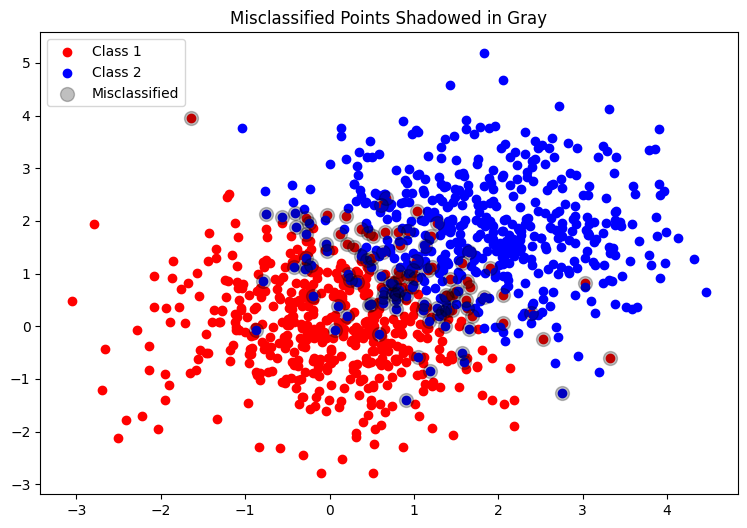

In [9]:
OFFSET = 1.75
np.random.seed(1)
xTe, yTe = toy_data(OFFSET, 1000)

# Compute Bayes classifier error
ybar = compute_ybar(xTe, OFFSET)
predictions = np.round(ybar)
errors = predictions != yTe
err = errors.sum() / len(yTe)
print(f"Bayes Classifier Error: {100 * err:.2f}%")

# Compute noise
noise = compute_noise(xTe, yTe, OFFSET)
print(f"Noise: {noise:.4f}")

# Plot test data
ind1 = yTe == 1
ind2 = yTe == 2
plt.figure(figsize=(9, 6))
plt.scatter(xTe[ind1, 0], xTe[ind1, 1], c="red", marker="o", label="Class 1")
plt.scatter(xTe[ind2, 0], xTe[ind2, 1], c="blue", marker="o", label="Class 2")
plt.scatter(
    xTe[errors, 0], xTe[errors, 1], c="black", s=100, alpha=0.25, label="Misclassified"
)
plt.title("Misclassified Points Shadowed in Gray")
plt.legend(loc="upper left")
plt.show()

As you can see from the graph above, the dataset is noisy and cannot be classified into two groups cleanly, thus giving non-zero noise and non-zero Bayes error!

### Part Three: Bias [Graded]

For the bias, you will need the average classifier $\overline{h}$. Although you cannot compute the expected value $\overline{h} = \mathbb{E}[h]$, you can approximate it by sampling many training sets $D_1, \dots, D_m$, and training a classifier on each to get $h_{D_1}, \dots, h_{D_m}$. You can then average their predictions on each data point:

$$
\overline{h}(\mathbf{x}) \approx \frac{1}{m} \sum_{j=1}^m h_{D_j}(\mathbf{x})
$$
    
Edit the function **`compute_hbar`** to do this. You should average over `NMODELS` ($m$) different $h_{D_j}$, each trained on a different data set of `Nsmall` ($n$) inputs drawn from the same distribution. You essentially need to create `NMODELS` toy datasets of size `Nsmall` using `toy_data(OFFSET, Nsmall)` and evaluate the trained classifier on `xTe`.

We are going to use regression trees as our $h_{D_j}$. The code in the next cell shows how to fit a decision tree and make predictions. Note that `depth=np.inf` means the regression tree has no restriction on its depth. If you wanted to create a tree of depth `k`, then you would call `RegressionTree(depth=k)`.

In [10]:
# Generate training data
xTr, yTr = toy_data(OFFSET, 100)

# Create a regression tree
tree = RegressionTree(depth=np.inf)

# Fit/train the regression tree
tree.fit(xTr, yTr)

# Use trained regression tree to make predictions
pred = tree.predict(xTr)

Your task is to implement the `compute_hbar` function in the next cell.

In [17]:
def compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET):
    """
    Computes the prediction of the average regression tree (hbar) on dataset xTe.
    Each of the NMODELS regression trees used in the average tree should be
    trained using data from toy_data(OFFSET, Nsmall).

    Input:
        xTe: Data matrix of shape nx2
        depth: Depth of each regression tree to be trained
        Nsmall: Number of points in the dataset that each tree is trained on
        NMODELS: Number of regression trees to train
        OFFSET: The OFFSET passed into the toyData function. The difference in the
                mu of normal distributions for points with labels class1 and class2.
    Output:
        hbar: a nx1 vector of the expected labels for each vector in xTe
    """
    n = xTe.shape[0]
    hbar = np.zeros(n)  # Initialize variable to be returned

    # YOUR CODE HERE
    for model in range(NMODELS):
        xTr, yTr = toy_data(OFFSET, Nsmall)
        # Create a regression tree
        tree = RegressionTree(depth=depth)
        # Fit/train the regression tree
        tree.fit(xTr, yTr)
        # Use trained regression tree to make predictions
        pred = tree.predict(xTe)
        hbar += pred
    hbar /= NMODELS
    # END OF YOUR CODE

    return hbar

Run the next cell to check your implementation of `compute_hbar`.

In [18]:
def hbar_test1():
    """
    Check that hbar has the correct shape
    """
    OFFSET = 2
    depth = 2
    Nsmall = 10
    NMODELS = 10
    n = 1000
    xTe, yTe = toy_data(OFFSET, n)
    hbar = compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET)
    return hbar.shape == (n,)


def hbar_test2():
    """
    Check that hbar has the correct value
    """
    OFFSET = 50
    depth = 2
    Nsmall = 10
    NMODELS = 1
    
    # First test dataset (means far away)
    xTe = np.array(
        [
            [49.308783, 49.620651],
            [1.705462, 1.885418],
            [51.192402, 50.256330],
            [0.205998, -0.089885],
            [50.853083, 51.833237],
        ]
    )
    yTe = np.array([2, 1, 2, 1, 2])

    hbar = compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET)
    ybar = compute_ybar_grader(xTe, OFFSET)

    return np.isclose(np.mean(np.power(hbar - ybar, 2)), 0)


def hbar_test3():
    """
    Another check that hbar has the correct value
    """
    OFFSET = 3
    depth = 3
    Nsmall = 10
    NMODELS = 100
    np.random.seed(1)

    # Second test dataset (means close together)
    xTe = np.array(
        [
            [0.45864, 0.71552],
            [2.44662, 1.68167],
            [1.00345, 0.15182],
            [-0.10560, -0.48155],
            [3.07264, 3.81535],
            [3.13035, 2.72151],
            [2.25265, 3.78697],
        ]
    )
    yTe = np.array([1, 2, 1, 1, 2, 2, 2])

    hbar = compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET)
    ybar = compute_ybar_grader(xTe, OFFSET)

    return np.abs(np.mean(np.power(hbar - ybar, 2)) - 0.0017) < 0.001


runtest(hbar_test1, "hbar_test1")
runtest(hbar_test2, "hbar_test2")
runtest(hbar_test3, "hbar_test3")

Running Test: hbar_test1 ... ✔ Passed!
Running Test: hbar_test2 ... ✔ Passed!
Running Test: hbar_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (hbar_test1)

In [ ]:
# Auto-graded test cell worth one point (hbar_test2)

In [ ]:
# Auto-graded test cell worth one point (hbar_test3)

### Part Four: Bias Continued [Graded]

Now we're equipped to calculate the bias term

$$\mathbb{E}\left[\left(\overline{h}(\mathbf{x})-\overline{y}(\mathbf{x}) \right)^2\right]
$$

In this case, you need to compute the mean of the squared difference over your input points:

$$
\mathbb{E}\left[\left(\overline{h}(\mathbf{x})-\overline{y}(\mathbf{x})\right)^2\right]
\approx \frac{1}{n}\sum_{i=1}^{n}\left(\overline{h}(\mathbf{x}_i)-\overline{y}(\mathbf{x}_i)\right)^2
$$

You can call both `compute_hbar` and `compute_ybar` to calculate the bias.

In [25]:
def compute_bias(xTe, depth, Nsmall, NMODELS, OFFSET):
    """
    Computes the bias for data set xTe.
    Each of the NMODELS regression trees used in the average tree should be
    trained using data from toy_data(OFFSET, Nsmall).

    Input:
        xTe: Data matrix of shape nx2
        depth: Depth of each regression tree to be trained
        Nsmall: Number of points in the dataset that each tree is trained on
        NMODELS: Number of regression trees to train
        OFFSET: The OFFSET passed into the toyData function.
                The difference in the mu of normal distributions
                for points with labels class1 and class2.

    Output:
        bias: Scalar representing the bias component of the error of xTe
    """
    bias = None  # Initialize variable to be returned

    # YOUR CODE HERE
    hbar = compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET)
    ybar = compute_ybar(xTe, OFFSET)
    bias = np.mean((hbar - ybar)**2)
    # END OF YOUR CODE
    return bias

Run the next cell to check your implementation of `compute_bias`.

In [26]:
def bias_test1():
    """
    Check that bias is a scalar
    """
    OFFSET = 2
    depth = 2
    Nsmall = 10
    NMODELS = 10
    n = 1000
    xTe, yTe = toy_data(OFFSET, n)
    bias = compute_bias(xTe, depth, Nsmall, NMODELS, OFFSET)
    return np.isscalar(bias)


def bias_test2():
    """
    Check that bias has the correct value
    """
    OFFSET = 50
    depth = 2
    Nsmall = 10
    NMODELS = 1
    
    # First test dataset (means far away)
    xTe = np.array(
        [
            [49.308783, 49.620651],
            [1.705462, 1.885418],
            [51.192402, 50.256330],
            [0.205998, -0.089885],
            [50.853083, 51.833237],
        ]
    )
    yTe = np.array([2, 1, 2, 1, 2])

    bias = compute_bias(xTe, depth, Nsmall, NMODELS, OFFSET)
    
    return np.isclose(bias, 0)


def bias_test3():
    """
    Another check that bias has the correct value
    """
    OFFSET = 3
    depth = 3
    Nsmall = 10
    NMODELS = 100
    np.random.seed(1)

    # Second test dataset (means close together)
    xTe = np.array(
        [
            [0.45864, 0.71552],
            [2.44662, 1.68167],
            [1.00345, 0.15182],
            [-0.10560, -0.48155],
            [3.07264, 3.81535],
            [3.13035, 2.72151],
            [2.25265, 3.78697],
        ]
    )
    yTe = np.array([1, 2, 1, 1, 2, 2, 2])

    bias = compute_bias(xTe, depth, Nsmall, NMODELS, OFFSET)
    
    return np.abs(bias - 0.0017) < 0.001


runtest(bias_test1, "bias_test1")
runtest(bias_test2, "bias_test2")
runtest(bias_test3, "bias_test3")

Running Test: bias_test1 ... ✔ Passed!
Running Test: bias_test2 ... ✔ Passed!
Running Test: bias_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (bias_test1)

In [ ]:
# Auto-graded test cell worth one point (bias_test2)

In [ ]:
# Auto-graded test cell worth one point (bias_test3)

### Part Five: Variance [Graded]

Finally, to compute the variance in **`compute_variance`**, you need to compute the term 

$$
\mathbb{E}\left[\left(h_D(\mathbf{x})-\overline{h}(\mathbf{x})\right)^2\right]
$$

The variance term is an expectation over $D$ and $\mathbf{x}$ and we can take a two-step approach. First, we fix any $\mathbf{x}_i$ and calculate 

$$
\overline{v}(\mathbf{x}_i) 
= \mathbb{E}\left[\left(h_D(\mathbf{x}_i) - \overline{h}(\mathbf{x}_i)\right)^2\right]
$$

Once again, you cannot compute the expected value exactly, but you can approximate this term by averaging over $m$ (`NMODELS`) models. You can use your implementation of `compute_hbar` to compute $\overline{h}$ and then estimate

$$
\overline{v}(\mathbf{x}_i) 
= \mathbb{E}\left[\left(h_D(\mathbf{x}_i) 
- \overline{h}(\mathbf{x}_i)\right)^2\right]
\approx \frac{1}{m} \sum_{j=1}^m \left(
h_{D_j}(\mathbf{x}_i) - \overline{h}(\mathbf{x})
\right)^2
$$

Here, $D_1,\dots, D_m$ are i.i.d. training data sets of size $n$ (`Nsmall`). Note that the output of this function is a $n$-dimensional vector; in other words, you should not be taking an average over the $n$ input points.

Finally, you will need to return the variance itself, which is

$$
\mathbb{E}\left[\left(h_D(\mathbf{x}) - \overline{h}(\mathbf{x})\right)^2\right]
= \mathbb{E}\left[\overline{v}(\mathbf{x})\right] 
\approx \frac{1}{n}\sum_{i=1}^{n} \overline{v}(\mathbf{x}_i)
$$

In [34]:
def compute_variance(xTe, depth, hbar, Nsmall, NMODELS, OFFSET):
    """
    Computes variance of classifiers trained on datasets from toy_data(OFFSET, Nsmall).
    The prediction of the average classifier is assumed to be stored in hbar.

    Input:
        xTe: Data matrix of shape nx2
        depth: Depth of each regression tree to be trained
        hbar: nx1 vector of the predictions of hbar on the inputs xTe
        Nsmall: Number of points in the dataset that each tree is trained on
        NMODELS: Number of regression trees to train
        OFFSET: The OFFSET passed into the toyData function.
                The difference in the mu of normal distributions
                for points with labels class1 and class2.

    Output:
        variance: Scalar representing the bias component of the error of xTe
    """
    n = xTe.shape[0]
    vbar = np.zeros(n)
    variance = None  # Initialize variable to be returned

    # YOUR CODE HERE
    for model in range(NMODELS):
        xTr, yTr = toy_data(OFFSET, Nsmall)
        # Create a regression tree
        tree = RegressionTree(depth=depth)
        # Fit/train the regression tree
        tree.fit(xTr, yTr)
        # Use trained regression tree to make predictions
        pred = tree.predict(xTe)
        vbar += (pred-hbar)**2
    vbar /= NMODELS
    variance = np.mean(vbar)
    # END OF YOUR CODE

    return variance

Run the next cell to check your implementation of `compute_variance`.

In [35]:
def variance_test1():
    """
    Check that variance is a scalar
    """
    OFFSET = 2
    depth = 2
    Nsmall = 10
    NMODELS = 10
    n = 1000
    xTe, yTe = toy_data(OFFSET, n)
    hbar = compute_hbar_grader(xTe, depth, Nsmall, NMODELS, OFFSET)
    var = compute_variance(xTe, depth, hbar, Nsmall, NMODELS, OFFSET)
    return np.isscalar(var)


def variance_test2():
    """
    Check that variance has the correct value
    """
    OFFSET = 50
    depth = 2
    Nsmall = 10
    NMODELS = 10

    # First test dataset (means far away)
    xTe = np.array(
        [
            [49.308783, 49.620651],
            [1.705462, 1.885418],
            [51.192402, 50.256330],
            [0.205998, -0.089885],
            [50.853083, 51.833237],
        ]
    )
    yTe = np.array([2, 1, 2, 1, 2])

    hbar = compute_hbar_grader(xTe, depth, Nsmall, NMODELS, OFFSET)
    var = compute_variance(xTe, depth, hbar, Nsmall, NMODELS, OFFSET)
    
    return np.isclose(var, 0)


def variance_test3():
    """
    Another check that variance has the correct value
    """
    OFFSET = 3
    depth = 3
    Nsmall = 10
    NMODELS = 100
    np.random.seed(1)

    # Second test dataset (means close together)
    xTe = np.array(
        [
            [0.45864, 0.71552],
            [2.44662, 1.68167],
            [1.00345, 0.15182],
            [-0.10560, -0.48155],
            [3.07264, 3.81535],
            [3.13035, 2.72151],
            [2.25265, 3.78697],
        ]
    )
    yTe = np.array([1, 2, 1, 1, 2, 2, 2])

    hbar = compute_hbar_grader(xTe, depth, Nsmall, NMODELS, OFFSET)
    var = compute_variance(xTe, depth, hbar, Nsmall, NMODELS, OFFSET)
    
    return np.abs(var - 0.0404) < 0.0015


runtest(variance_test1, "variance_test1")
runtest(variance_test2, "variance_test2")
runtest(variance_test3, "variance_test3")

Running Test: variance_test1 ... ✔ Passed!
Running Test: variance_test2 ... ✔ Passed!
Running Test: variance_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (variance_test1)

In [ ]:
# Auto-graded test cell worth one point (variance_test2)

In [ ]:
# Auto-graded test cell worth one point (variance_test3)

### Compare the Error to Bias + Variance + Noise for Various Depths

If you did everything in the three previous graded sections correctly and execute the following cell, you should see how the error decomposes (roughly) into bias, variance, and noise for various depths.

**NOTE:** The next cell takes about half a minute to run.

In [36]:
# Mean value of training and testing datasets
OFFSET = 1.75

# Size of small training dataset
Nsmall = 75

# Size of large testing dataset (approx. infinity)
Nbig = 7500

# Number of models used for computations
NMODELS = 100

# Depths to use for the models
depths = [0, 1, 2, 3, 4, 5, 6, np.inf]

# Initialize variables
Ndepths = len(depths)
lbias = np.zeros(Ndepths)
lvariance = np.zeros(Ndepths)
lnoise = np.zeros(Ndepths)
lsum = np.zeros(Ndepths)
lerror = np.zeros(Ndepths)

# Evaluate classifier models of different depths
for i in range(Ndepths):
    depth = depths[i]
    
    # Dataset to use as an approximation of the true test dataset
    xTe, yTe = toy_data(OFFSET, Nbig)

    # Estimate variance
    hbar = compute_hbar(xTe, depth, Nsmall, NMODELS, OFFSET)
    variance = compute_variance(xTe, depth, hbar, Nsmall, NMODELS, OFFSET)

    # Estimate bias
    bias = compute_bias(xTe, depth, Nsmall, NMODELS, OFFSET)

    # Estimate noise
    noise = compute_noise(xTe, yTe, OFFSET)

    # Estimate generalized error (average mean squared error)
    error = 0
    
    for j in range(NMODELS):
        xTr2, yTr2 = toy_data(OFFSET, Nsmall)
        model = RegressionTree(depth=depth)
        model.fit(xTr2, yTr2)
        error += np.mean((model.predict(xTe) - yTe) ** 2)
    
    error /= NMODELS

    # Store results for bias, variance, noise, and error
    lbias[i] = bias
    lvariance[i] = variance
    lnoise[i] = noise
    lsum[i] = lbias[i] + lvariance[i] + lnoise[i]
    lerror[i] = error

    # Print results for bias, variance, noise, and error
    if np.isinf(depths[i]):
        print(
            f"Depth infinite - Var: {lvariance[i]:.4f}, Bias: {lbias[i]:.4f}, ",
            f"Noise: {lnoise[i]:.4f}, Var+Bias+Noise: {lsum[i]:.4f}, ",
            f"Error: {lerror[i]:.4f}",
        )
    else:
        print(
            f"Depth {depths[i]} - Var: {lvariance[i]:.4f}, Bias: {lbias[i]:.4f}, ",
            f"Noise: {lnoise[i]:.4f}, Var+Bias+Noise: {lsum[i]:.4f}, ",
            f"Error: {lerror[i]:.4f}",
        )

Depth 0 - Var: 0.0000, Bias: 0.1716,  Noise: 0.0764, Var+Bias+Noise: 0.2480,  Error: 0.2500
Depth 1 - Var: 0.0551, Bias: 0.0297,  Noise: 0.0792, Var+Bias+Noise: 0.1640,  Error: 0.1637
Depth 2 - Var: 0.0415, Bias: 0.0055,  Noise: 0.0771, Var+Bias+Noise: 0.1241,  Error: 0.1231
Depth 3 - Var: 0.0500, Bias: 0.0028,  Noise: 0.0770, Var+Bias+Noise: 0.1298,  Error: 0.1262
Depth 4 - Var: 0.0721, Bias: 0.0028,  Noise: 0.0820, Var+Bias+Noise: 0.1569,  Error: 0.1537
Depth 5 - Var: 0.0778, Bias: 0.0028,  Noise: 0.0768, Var+Bias+Noise: 0.1575,  Error: 0.1557
Depth 6 - Var: 0.0862, Bias: 0.0026,  Noise: 0.0783, Var+Bias+Noise: 0.1672,  Error: 0.1634
Depth infinite - Var: 0.0902, Bias: 0.0028,  Noise: 0.0782, Var+Bias+Noise: 0.1712,  Error: 0.1673


When the depth increases, notice that the variance goes up as the bias goes down and the noise is roughly the same &mdash; but the decomposition `Var+Bias+Noise` is always close to the `Error` values (as expected).

Run the next cell to plot the results of the previous cell.

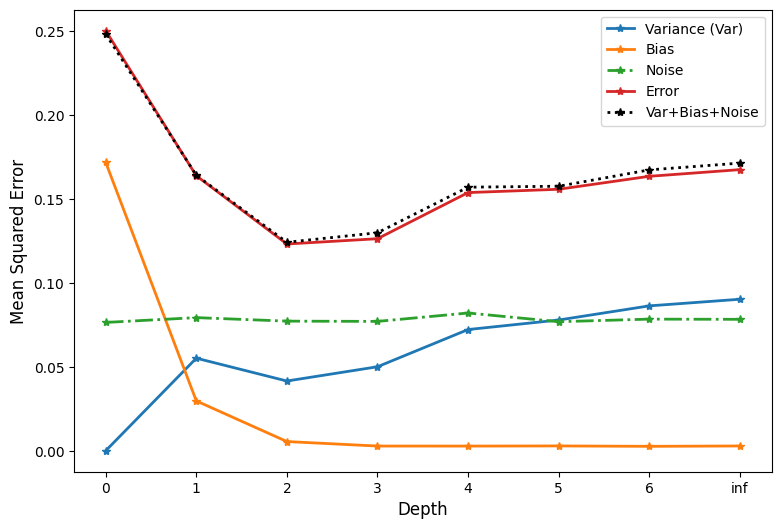

In [37]:
plt.figure(figsize=(9, 6))

plt.plot(lvariance[:Ndepths], "*", linestyle="-", linewidth=2, label="Variance (Var)")
plt.plot(lbias[:Ndepths], "*", linestyle="-", linewidth=2, label="Bias")
plt.plot(lnoise[:Ndepths], "*", linestyle="-.", linewidth=2, label="Noise")
plt.plot(lerror[:Ndepths], "*", linestyle="-", linewidth=2, label="Error")
plt.plot(lsum[:Ndepths], "*", c="black", linestyle="dotted", linewidth=2, label="Var+Bias+Noise")

plt.legend(loc="upper right")
plt.xlabel("Depth", fontsize=12)
plt.ylabel("Mean Squared Error", fontsize=12)
plt.xticks([i for i in range(Ndepths)], depths);